In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1.0 Análisis del data frame

## 1. Leer el data frame

- En formato csv en la dirección https://raw.githubusercontent.com/hernansalinas/Curso_aprendizaje_estadistico/main/datasets/Sesion_07_housing.csv


In [2]:
# URL of the dataset
url = 'https://raw.githubusercontent.com/hernansalinas/Curso_aprendizaje_estadistico/main/datasets/Sesion_07_housing.csv'

# Load the dataframe
df = pd.read_csv(url)

# Display the first few rows
display(df.head())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 2. Entender el estado de los datos
- Para ello puedo emplear los comandos básicos del pandas

- df.info()
- df.describe()
- df.isnull().sum(
)

In [3]:
# 2. Entender el estado de los datos
print("=== INFORMACIÓN GENERAL ===")
df.info()

print("\n=== ESTADÍSTICAS DESCRIPTIVAS ===")
display(df.describe())

print("\n=== VALORES NULOS ===")
display(df.isnull().sum())

=== INFORMACIÓN GENERAL ===
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB

=== ESTADÍSTICAS DESCRIPTIVAS ===


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000



=== VALORES NULOS ===


longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

## 3. ¿Cuántas variables tiene el dataset y de qué tipo son?
## 4. ¿Existen valores faltantes? ¿En qué variables estan? ¿cuántos son?

In [4]:
# 3. ¿Cuántas variables tiene el dataset y de qué tipo son?
num_variables = df.shape[1]
tipos_variables = df.dtypes

print(f"El dataset tiene {num_variables} variables.\n")
print("Tipos de variables:")
print(tipos_variables)

print("\n" + "="*40 + "\n")

# 4. ¿Existen valores faltantes? ¿En qué variables están? ¿cuántos son?
valores_faltantes = df.isnull().sum()
variables_con_faltantes = valores_faltantes[valores_faltantes > 0]

if not variables_con_faltantes.empty:
    print("Sí, existen valores faltantes en las siguientes variables:")
    for var, cant in variables_con_faltantes.items():
        print(f"- {var}: {cant} valores faltantes")
else:
    print("No existen valores faltantes en el dataset.")

El dataset tiene 10 variables.

Tipos de variables:
longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity           str
dtype: object


Sí, existen valores faltantes en las siguientes variables:
- total_bedrooms: 207 valores faltantes


## 5. Determinar los elementos únicos dentro de la columna ocean_proximity.


In [5]:
# 5. Determinar los elementos únicos dentro de la columna ocean_proximity
valores_unicos = df['ocean_proximity'].unique()
print("Elementos únicos en 'ocean_proximity':")
print(valores_unicos)

Elementos únicos en 'ocean_proximity':
<StringArray>
['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND']
Length: 5, dtype: str


## 6 Promedio segundo elemento unico de ocean_proximity

Para las columnas

```python
cols = ["housing_median_age",	"total_rooms",	"total_bedrooms",	"population",	"households",	"median_income",	"median_house_value"]
```

Determinar el promedio de cada una de las columnas asociado a cada elementos unico de ocean_proximity, intenta con la operación groupby.


In [6]:
# 6. Promedio por cada elemento único de ocean_proximity
cols = ["housing_median_age", "total_rooms", "total_bedrooms", "population", "households", "median_income", "median_house_value"]

# Agrupar por 'ocean_proximity' y calcular la media de las columnas seleccionadas
promedios_por_proximidad = df.groupby('ocean_proximity')[cols].mean()

display(promedios_por_proximidad)

,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
ocean_proximity,,,,,,,
<1H OCEAN,29.279225,2628.343586,546.539185,1520.290499,517.744965,4.230682,240084.285464
INLAND,24.271867,2717.742787,533.881619,1391.046252,477.447565,3.208996,124805.392001
ISLAND,42.400000,1574.600000,420.400000,668.000000,276.600000,2.744420,380440.000000
NEAR BAY,37.730131,2493.589520,514.182819,1230.317467,488.616157,4.172885,259212.311790
NEAR OCEAN,29.347254,2583.700903,538.615677,1354.008653,501.244545,4.005785,249433.977427


## 7. Histogramas para cada columna con Seaborn

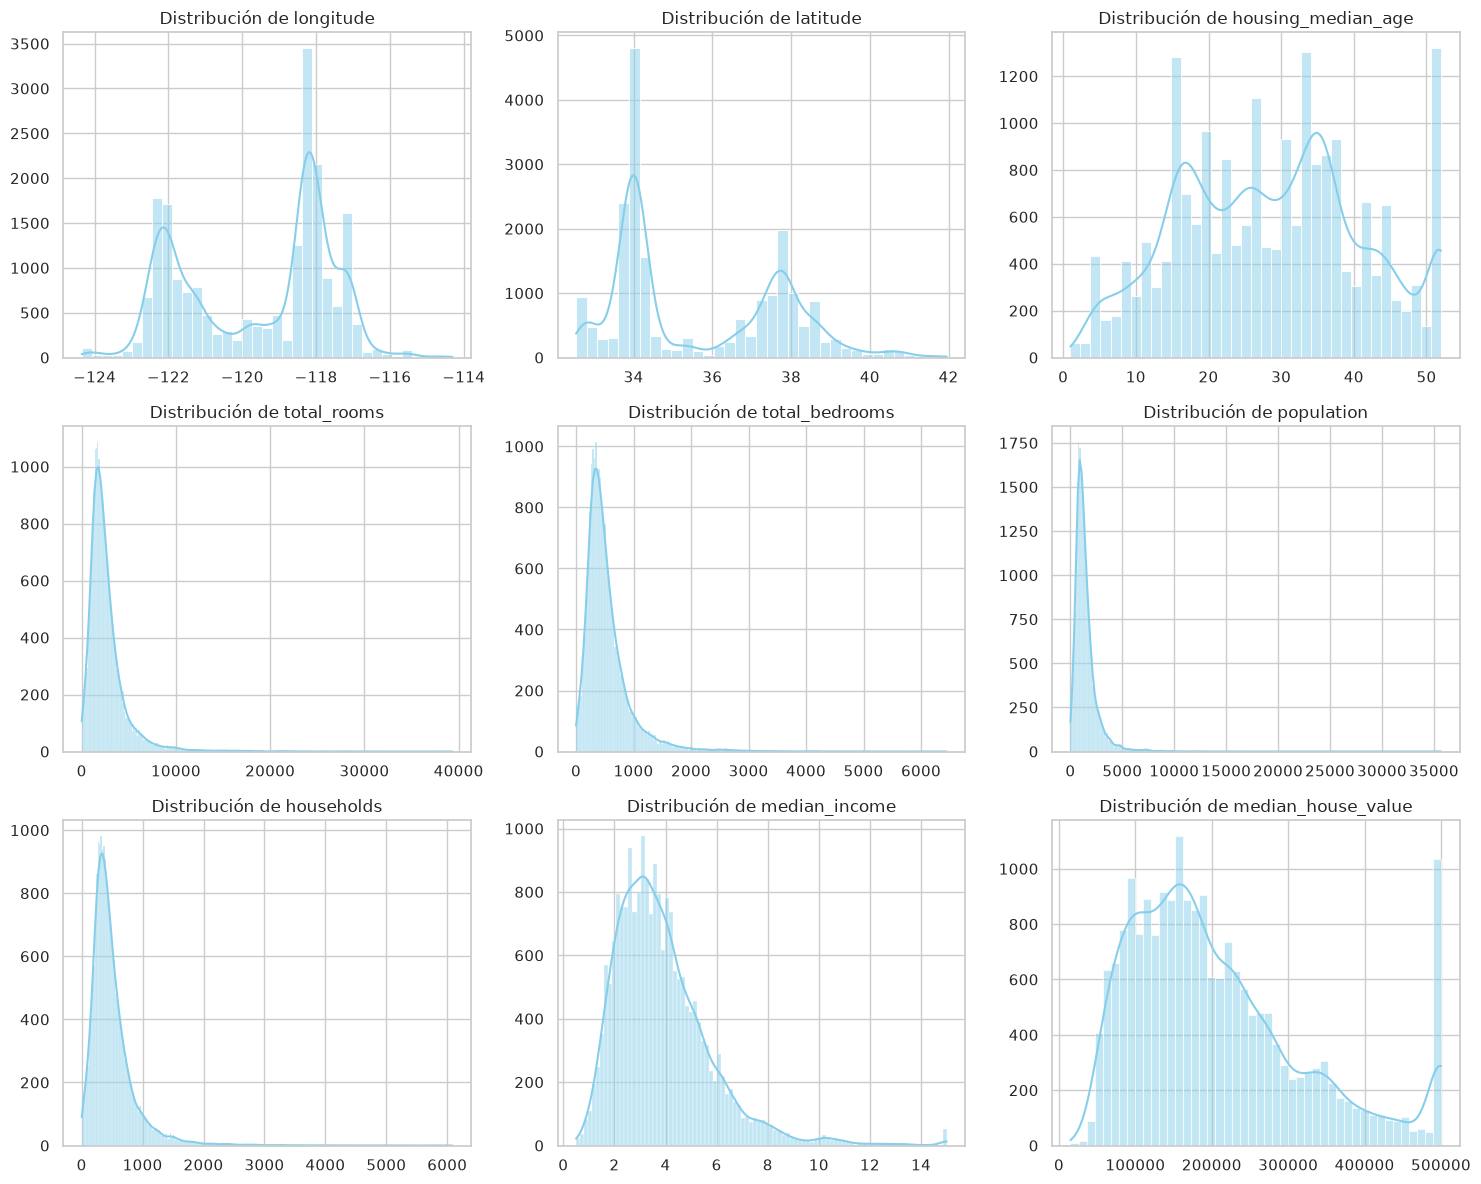

In [7]:
# Obtener las columnas numéricas para graficar sus histogramas
columnas_numericas = df.select_dtypes(include=['float64', 'int64']).columns

# Configurar el estilo de seaborn
sns.set_theme(style="whitegrid")

# Crear subplots para cada variable
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(columnas_numericas):
    if i < len(axes):
        sns.histplot(df[col], ax=axes[i], kde=True, color='skyblue')
        axes[i].set_title(f'Distribución de {col}')
        axes[i].set_xlabel('')
        axes[i].set_ylabel('')

# Ajustar el diseño para que no se superpongan
plt.tight_layout()
plt.show()

## 8. Boxplot para comparar el valor de la vivienda por proximidad al océano

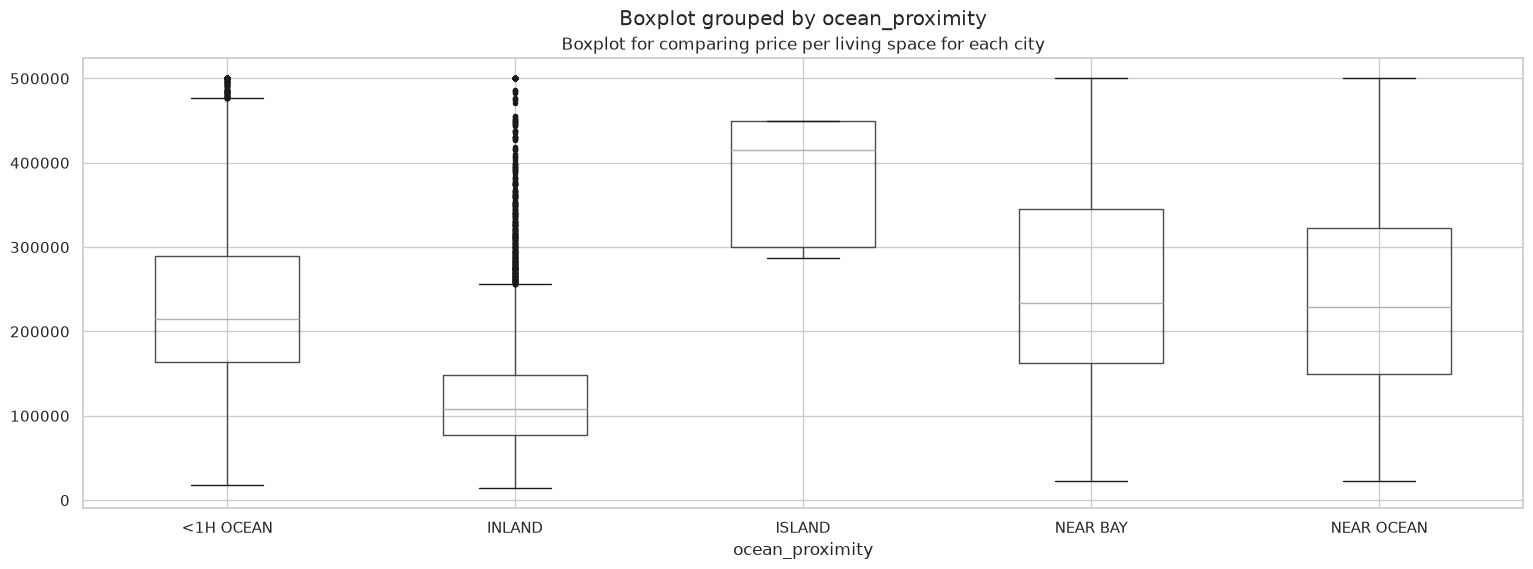

In [8]:
#draw boxplot
df.boxplot(column="median_house_value", by='ocean_proximity', sym = 'k.', figsize=(18,6))
#set title
plt.title('Boxplot for comparing price per living space for each city')
plt.show()

## 9. Determinar la matriz de correlación

Calcularemos la matriz de correlación para las variables numéricas y crearemos un mapa de calor (*heatmap*) para visualizar las relaciones.

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924664,-0.108197,0.044568,0.069608,0.099773,0.055310,-0.015176,-0.045967
latitude,-0.924664,1.000000,0.011173,-0.036100,-0.066983,-0.108785,-0.071035,-0.079809,-0.144160
housing_median_age,-0.108197,0.011173,1.000000,-0.361262,-0.320451,-0.296244,-0.302916,-0.119034,0.105623
total_rooms,0.044568,-0.036100,-0.361262,1.000000,0.930380,0.857126,0.918484,0.198050,0.134153
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686
population,0.099773,-0.108785,-0.296244,0.857126,0.877747,1.000000,0.907222,0.004834,-0.024650
households,0.055310,-0.071035,-0.302916,0.918484,0.979728,0.907222,1.000000,0.013033,0.065843
median_income,-0.015176,-0.079809,-0.119034,0.198050,-0.007723,0.004834,0.013033,1.000000,0.688075
median_house_value,-0.045967,-0.144160,0.105623,0.134153,0.049686,-0.024650,0.065843,0.688075,1.000000


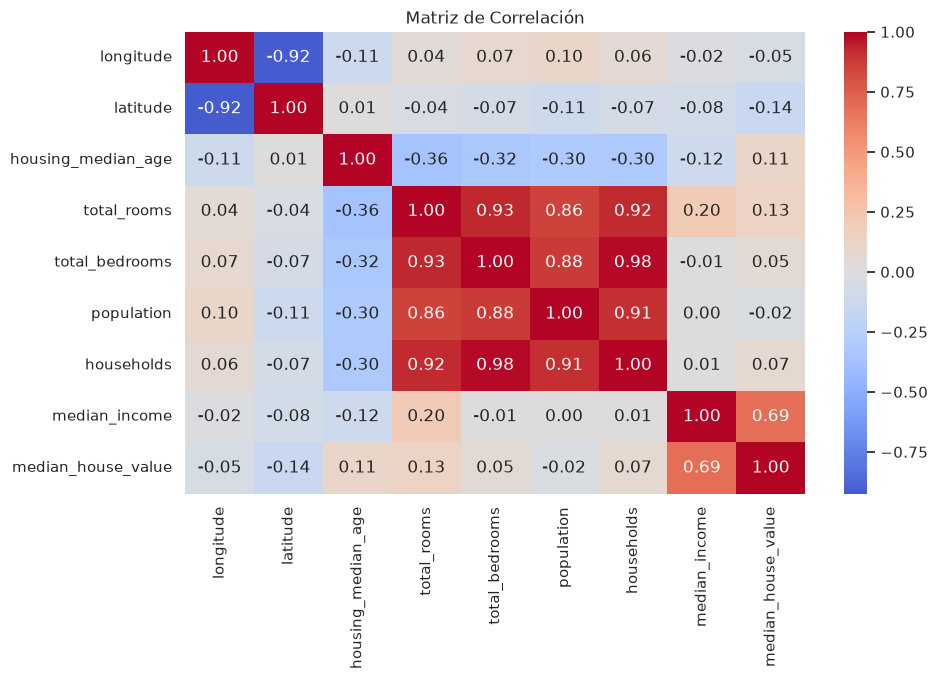

In [9]:
# Calcular la matriz de correlación (excluyendo columnas no numéricas automáticamente con numeric_only=True)
corr_matrix = df.corr(numeric_only=True)
display(corr_matrix)

# Visualizar la matriz de correlación con un mapa de calor
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Matriz de Correlación")
plt.show()

## 10. Gráfico de dispersión múltiple (Pairplot) con Seaborn

Crearemos un gráfico `pairplot` para analizar las relaciones simultáneas entre un subconjunto clave de variables.

- En la diagonal (Gráficos de densidad/KDE): Nos muestra la distribución individual de cada una de las variables seleccionadas (median_house_value, median_income, total_rooms y housing_median_age).
- Fuera de la diagonal (Gráficos de dispersión/Scatter plots): Nos muestra la relación cruzada o conjunta entre cada par de variables.

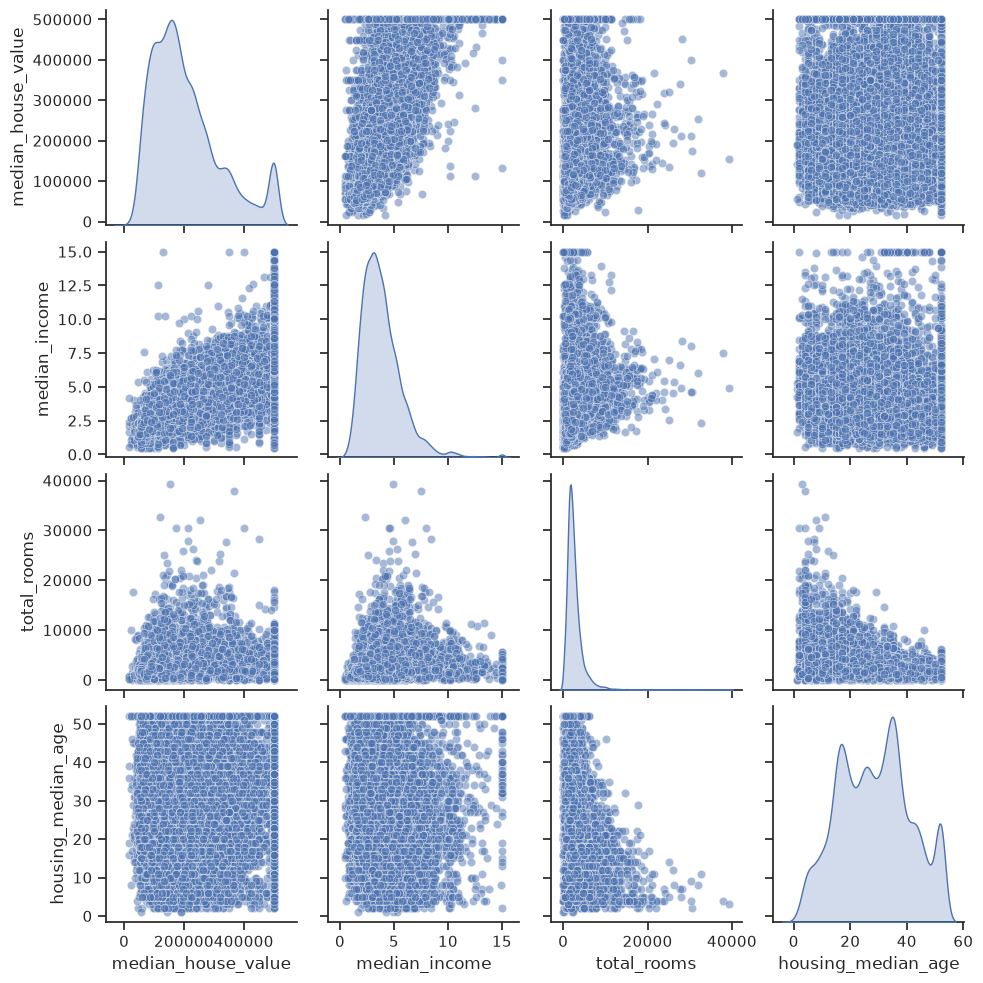

In [10]:
# Columnas seleccionadas para el pairplot
cols = ["median_house_value", "median_income", "total_rooms", "housing_median_age"]

# Crear el gráfico pairplot
sns.set_theme(style="ticks")
pairplot_fig = sns.pairplot(df[cols], diag_kind="kde", plot_kws={'alpha': 0.5})
plt.show()

## 11. Gráfico de dispersión geográfica (Scatter Plot)

Crearemos un gráfico de dispersión utilizando las coordenadas geográficas (`longitude` y `latitude`) y representaremos el valor de la vivienda (`median_house_value`) a través de la escala de colores.

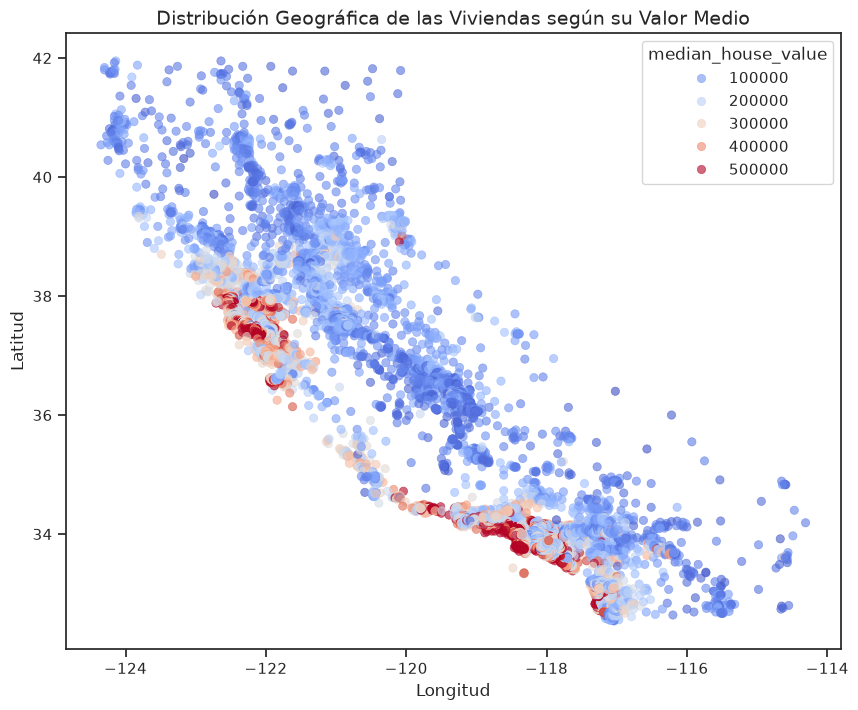

In [11]:
# Configurar el tamaño de la figura
plt.figure(figsize=(10, 8))

# Crear el gráfico de dispersión con Seaborn
scatter = sns.scatterplot(
    data=df,
    x="longitude",
    y="latitude",
    hue="median_house_value",
    palette="coolwarm",
    alpha=0.6,
    edgecolor=None
)

# Configurar títulos y etiquetas
plt.title("Distribución Geográfica de las Viviendas según su Valor Medio", fontsize=14)
plt.xlabel("Longitud", fontsize=12)
plt.ylabel("Latitud", fontsize=12)

# Mostrar el gráfico
plt.show()

12. ¿Las siguiente linea es adecuada para separar el dataframe en datos de entrenamiento de test?, ¿que pasa en la división de los datos?



In [ ]:
from sklearn.model_selection import train_test_split

# ¿Es significativa la muestra que se esta considerando?
train_set, test_set \
  = train_test_split(df, test_size = 0.2, random_state = 42)

print(len(train_set))
print(len(test_set))


ModuleNotFoundError: No module named 'sklearn'

- Este codigo anterior divide el dataset en dos conjuntos, el conjunto de los datos de entrenamiento que tiene el 80% de las filas del dataset y el conjuto de testeo tiene el 20% restante.
- Esta división permite que el modelo se entrene pues tiene suficientes datos, pero el codigo escoge las filas aleatoriamente, dando depronto un sesgo a los datos.


## 13. División del dataset en grupos:


In [ ]:
import numpy as np
from sklearn.model_selection import StratifiedShuffleSplit

# 1. Crear la columna 'income_cat' limitando el número de categorías de ingresos
df["income_cat"] = pd.cut(df["median_income"],
                               bins=[0., 1.5, 3.0, 4.5, 6.0, np.inf],
                               labels=[1, 2, 3, 4, 5])

# 2. Realizar la división estratificada basada en la categoría de ingresos
split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
for train_index, test_index in split.split(df, df["income_cat"]):
    strat_train_set = df.loc[train_index]
    strat_test_set = df.loc[test_index]

# 3. Realizar la división puramente aleatoria propuesta (random_state=7)
train_set, test_set = train_test_split(df, test_size=0.2, random_state=7)

In [ ]:
# 4. Calcular y comparar las proporciones de las categorías de ingresos
proporciones = pd.DataFrame({
    "Completo (%)": df["income_cat"].value_counts() / len(df) * 100,
    "Estratificado Entreno (%)": strat_train_set["income_cat"].value_counts() / len(strat_train_set) * 100,
    "Estratificado Testeo (%)": strat_test_set["income_cat"].value_counts() / len(strat_test_set) * 100,
    "Aleatorio Entreno (%)": train_set["income_cat"].value_counts() / len(train_set) * 100
}).sort_index()

display(proporciones)

,Completo (%),Estratificado Entreno (%),Estratificado Testeo (%),Aleatorio Entreno (%)
income_cat,,,,
1,3.982558,3.978924,3.997093,3.978924
2,31.884690,31.885901,31.879845,32.418847
3,35.058140,35.059351,35.053295,34.871609
4,17.630814,17.629603,17.635659,17.314680
5,11.443798,11.446221,11.434109,11.415940


### Conclusiones de la Comparación de Proporciones (Muestreo Estratificado vs Aleatorio)

Al analizar la tabla de proporciones de las categorías de ingresos (`income_cat`), podemos extraer las siguientes conclusiones clave:

1. **Preservación de Proporciones mediante Muestreo Estratificado:**
   * Las proporciones en los conjuntos creados con **Muestreo Estratificado** (`Estratificado Entreno` y `Estratificado Testeo`) son virtualmente idénticas a las del dataset original (`Completo`).
   * Por ejemplo, la categoría 3 representa el **35.05%** en el dataset completo, y mantiene un **35.05%** exacto tanto en el entrenamiento como en el testeo estratificado.

2. **Sesgo en el Muestreo Aleatorio:**
   * El conjunto generado mediante división puramente aleatoria (`Aleatorio Entreno`) muestra desviaciones notables.
   * La categoría 2 sube del **31.88%** al **32.41%**, mientras que la categoría 3 baja del **35.05%** al **34.87%**.

3. **Importancia para el Modelado:**
   * Si utilizáramos una división puramente aleatoria, correríamos el riesgo de subrepresentar o sobrerepresentar estratos socioeconómicos críticos (ya que el ingreso es el predictor más fuerte del valor de la vivienda en este dataset).
   * El **muestreo estratificado** es indispensable aquí para asegurar que tanto el entrenamiento como la validación final del modelo se realicen sobre subconjuntos verdaderamente representativos de la población real.

In [ ]:
def income_cat_proportions(data):
    return data["income_cat"].value_counts() / len(data)

train_set, test_set = train_test_split(df, test_size=0.2, random_state=42)

compare_props = pd.DataFrame({
    "Overall": income_cat_proportions(df),
    "Stratified": income_cat_proportions(strat_test_set),
    "Random": income_cat_proportions(test_set),
}).sort_index()

compare_props["Rand. %error"] = abs(100 * compare_props["Random"] / compare_props["Overall"] - 100)
compare_props["Strat. %error"] = abs(100 * compare_props["Stratified"] / compare_props["Overall"] - 100)

display(compare_props)

,Overall,Stratified,Random,Rand. %error,Strat. %error
income_cat,,,,,
1,0.039826,0.039971,0.040213,0.973236,0.364964
2,0.318847,0.318798,0.324370,1.732260,0.015195
3,0.350581,0.350533,0.358527,2.266446,0.013820
4,0.176308,0.176357,0.167393,5.056334,0.027480
5,0.114438,0.114341,0.109496,4.318374,0.084674


Con este codigo podemos ver:
- Que los errores del muestreo estratificado (Strat. %error) son extremadamente cercanos a 0% (por lo general, menores al 1%).

- Que los errores del muestreo puramente aleatorio (Rand. %error) son significativamente más altos en proporción, demostrando matemáticamente la superioridad del método estratificado para mantener la representatividad de la población.

## 14. Comparación de Estadísticas del Imputador frente a las Medianas

In [ ]:
from sklearn.impute import SimpleImputer

# Eliminar 'ocean_proximity' y también la columna temporal 'income_cat'
df_train_num = strat_train_set.drop(["ocean_proximity", "income_cat"], axis=1)

# Crear y ajustar el imputador
imp_mean = SimpleImputer(strategy="median")
imp_mean.fit(df_train_num)

# Imprimir y comparar ambos resultados
print("Valores calculados por el imputador (imp_mean.statistics_):")
print(imp_mean.statistics_)

print("\nMedianas calculadas por pandas (df_train_num.median()):")
print(df_train_num.median().values)

# Ahora ambos vectores tienen exactamente 9 elementos, por lo que la comparación funcionará perfectamente
coinciden = np.allclose(imp_mean.statistics_, df_train_num.median().values)
print(f"\n¿Todos los valores coinciden exactamente?: {coinciden}")

Valores calculados por el imputador (imp_mean.statistics_):
[-1.18510e+02  3.42600e+01  2.90000e+01  2.11900e+03  4.33000e+02
  1.16400e+03  4.08000e+02  3.54155e+00  1.79500e+05]

Medianas calculadas por pandas (df_train_num.median()):
[-1.18510e+02  3.42600e+01  2.90000e+01  2.11900e+03  4.33000e+02
  1.16400e+03  4.08000e+02  3.54155e+00  1.79500e+05]

¿Todos los valores coinciden exactamente?: True


## Construcción de la matriz de características preparadas (housing_tr)

In [ ]:
# Transformamos el dataframe numérico reemplazando los valores nulos con las medianas aprendidas
X = imp_mean.transform(df_train_num)

# Convertimos el arreglo de numpy resultante de nuevo a un DataFrame de pandas
housing_tr = pd.DataFrame(X, columns=df_train_num.columns, index=df_train_num.index)

# Mostrar las primeras filas del nuevo DataFrame preparado
display(housing_tr.head())

# Verificar que ya no queden valores nulos en el conjunto preparado
print("\nValores nulos en housing_tr:")
print(housing_tr.isnull().sum())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
12655,-121.46,38.52,29.0,3873.0,797.0,2237.0,706.0,2.1736,72100.0
15502,-117.23,33.09,7.0,5320.0,855.0,2015.0,768.0,6.3373,279600.0
2908,-119.04,35.37,44.0,1618.0,310.0,667.0,300.0,2.8750,82700.0
14053,-117.13,32.75,24.0,1877.0,519.0,898.0,483.0,2.2264,112500.0
20496,-118.70,34.28,27.0,3536.0,646.0,1837.0,580.0,4.4964,238300.0



Valores nulos en housing_tr:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
dtype: int64


## 15. Manejo de texto y atributos categóricos: One-Hot Encoding

Vamos a aplicar el codificador `OneHotEncoder` de scikit-learn sobre la variable categórica `ocean_proximity` del conjunto de entrenamiento estratificado y a fusionar estas variables indicadoras binarias con nuestro dataset numérico imputado (`housing_tr`).

In [ ]:
from sklearn.preprocessing import OneHotEncoder

# 1. Extraer la variable categórica como un DataFrame de 2D
housing_cat = strat_train_set[["ocean_proximity"]]

# 2. Inicializar el codificador (sparse_output=False nos devuelve una matriz normal de numpy)
cat_encoder = OneHotEncoder(sparse_output=False)
housing_cat_1hot = cat_encoder.fit_transform(housing_cat)

print("Matriz resultante (primeras 5 filas):")
print(housing_cat_1hot[:5])

print("\nCategorías identificadas por el codificador:")
print(cat_encoder.categories_)

# 3. Convertir la matriz de numpy resultante a un DataFrame estructurado de pandas
df_cat_1hot = pd.DataFrame(housing_cat_1hot, columns=cat_encoder.categories_[0], index=strat_train_set.index)

# 4. Unir el DataFrame numérico preparado (housing_tr) con las nuevas variables binarias
housing_tr_ = housing_tr.join(df_cat_1hot)

# Mostrar el DataFrame final resultante listo para modelado
display(housing_tr_.head())

Matriz resultante (primeras 5 filas):
[[0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [1. 0. 0. 0. 0.]]

Categorías identificadas por el codificador:
[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
      dtype=object)]


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
12655,-121.46,38.52,29.0,3873.0,797.0,2237.0,706.0,2.1736,72100.0,0.0,1.0,0.0,0.0,0.0
15502,-117.23,33.09,7.0,5320.0,855.0,2015.0,768.0,6.3373,279600.0,0.0,0.0,0.0,0.0,1.0
2908,-119.04,35.37,44.0,1618.0,310.0,667.0,300.0,2.8750,82700.0,0.0,1.0,0.0,0.0,0.0
14053,-117.13,32.75,24.0,1877.0,519.0,898.0,483.0,2.2264,112500.0,0.0,0.0,0.0,0.0,1.0
20496,-118.70,34.28,27.0,3536.0,646.0,1837.0,580.0,4.4964,238300.0,1.0,0.0,0.0,0.0,0.0


### Resumen del procesamiento de variables categóricas:

1. **Aísla la columna categórica:** Selecciona únicamente la variable de texto `ocean_proximity` (`housing_cat`) del conjunto de entrenamiento en un formato de tabla bidimensional.
2. **Aplica Codificación One-Hot (`OneHotEncoder`):**
   * Analiza todas las categorías de ubicación de la columna (como `'INLAND'`, `'NEAR BAY'`, etc.).
   * Convierte cada categoría en una representación numérica binaria (columnas de ceros y unos). Cada valor de texto ahora se representa con un `1` en su columna correspondiente y un `0` en las demás.
3. **Crea un nuevo DataFrame:** Toma esa matriz binaria resultante de NumPy y la estructura en un DataFrame de Pandas, asignándole como nombres de columna las categorías encontradas.
4. **Une los datos:** Fusiona (`join`) estas nuevas columnas binarias indicadoras con las variables numéricas que ya habían sido previamente limpiadas e imputadas (`housing_tr`).

**En resumen:** Transforma la columna de texto original en columnas numéricas de ceros y unos para que los modelos de machine learning puedan interpretar la información geográfica, y la integra al dataset principal listo para entrenar.

In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Definir el orden de las columnas a escalar
cols = ["longitude", "latitude", "housing_median_age", "total_rooms",\
      "total_bedrooms", "population", "households", "median_income",\
      "<1H OCEAN", "INLAND", "ISLAND", "NEAR BAY", "NEAR OCEAN"]

# Seleccionar el conjunto de datos integrado
housing_scale = housing_tr_[cols]

# Inicializar y ajustar el escalador MinMax
scaler = MinMaxScaler()
scaler.fit(housing_scale)

# Transformar las variables al rango [0, 1]
X = scaler.transform(housing_scale)

# Reconstruir el DataFrame de pandas con los datos escalados
housing_prepared = pd.DataFrame(X, columns=housing_scale.columns, index=housing_scale.index)

# Mostrar el resultado final
display(housing_prepared.head())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
12655,0.287849,0.635494,0.549020,0.098362,0.128061,0.062614,0.131441,0.115426,0.0,1.0,0.0,0.0,0.0
15502,0.709163,0.058448,0.117647,0.135168,0.137403,0.056392,0.143017,0.402574,0.0,0.0,0.0,0.0,1.0
2908,0.528884,0.300744,0.843137,0.041003,0.049613,0.018610,0.055639,0.163798,0.0,1.0,0.0,0.0,0.0
14053,0.719124,0.022317,0.450980,0.047591,0.083280,0.025085,0.089806,0.119067,0.0,0.0,0.0,0.0,1.0
20496,0.562749,0.184910,0.509804,0.089790,0.103737,0.051403,0.107916,0.275617,1.0,0.0,0.0,0.0,0.0


## 17. Preparación completa de los datos y evaluación del modelo

Se utiliza una división estratificada basada en `income_cat`. La variable objetivo (`median_house_value`) se separa antes de ajustar las transformaciones para evitar fuga de información.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# La estratificación conserva la distribución de ingresos en train y test
train_set, test_set = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df["income_cat"]
)

# Separar predictores y variable objetivo
target = "median_house_value"
X_train = train_set.drop(columns=[target, "income_cat"])
y_train = train_set[target].copy()
X_test = test_set.drop(columns=[target, "income_cat"])
y_test = test_set[target].copy()

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Ajustar únicamente con train y transformar train/test con la misma preparación
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

housing_train = pd.DataFrame(X_train_prepared, columns=feature_names, index=X_train.index)
housing_train[target] = y_train
housing_test = pd.DataFrame(X_test_prepared, columns=feature_names, index=X_test.index)
housing_test[target] = y_test

print(f"Filas y columnas de housing_train: {housing_train.shape}")
print(f"Filas y columnas de housing_test: {housing_test.shape}")
display(housing_train.head())
display(housing_test.head())

### Evaluación de una regresión lineal

1. La regresión lineal es un modelo base válido porque la variable objetivo es continua; sin embargo, puede ser insuficiente si las relaciones son no lineales.
2. `R²` indica la proporción de variabilidad del precio explicada por el modelo. Un valor cercano a 1 es mejor, mientras que un valor cercano a 0 indica poca capacidad explicativa.
3. También se reportan RMSE y MAE; ambos están expresados en las unidades del precio y valores menores indican menor error.

In [ ]:
# El modelo se entrena sobre las características ya preparadas
linear_model = LinearRegression()
linear_model.fit(X_train_prepared, y_train)
y_pred = linear_model.predict(X_test_prepared)

metrics = pd.Series({
    "R²": r2_score(y_test, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
    "MAE": mean_absolute_error(y_test, y_pred)
})
display(metrics)

### Comparación con otro modelo y automatización

La regresión lineal puede ajustarse o sustituirse por modelos no lineales, como `RandomForestRegressor`. El pipeline siguiente encapsula la limpieza, imputación, codificación, escalamiento y entrenamiento en un único objeto reutilizable.

In [ ]:
# Pipeline completo: preprocesamiento + modelo no lineal
forest_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100, random_state=42, n_jobs=-1
    ))
])

forest_pipeline.fit(X_train, y_train)
forest_pred = forest_pipeline.predict(X_test)

comparison = pd.DataFrame({
    "Modelo": ["Regresión lineal", "Random Forest"],
    "R²": [r2_score(y_test, y_pred), r2_score(y_test, forest_pred)],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred)),
        np.sqrt(mean_squared_error(y_test, forest_pred))
    ],
    "MAE": [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test, forest_pred)
    ]
})

display(comparison)